# Session 7: PCA and collaborative filtering

**Course link:** Machine Learning Specialization, Course 3 Week 2 (collaborative filtering: learned features, the cost function, mean normalization, cold start, TensorFlow `GradientTape` and Adam; content-based filtering; PCA: principal components, explained variance, projection, reconstruction).

**Questions:**
1. What do the 26 countries look like in one picture?
2. Can collaborative filtering predict missing one-year TFP growth better than simple averages?

**Choices made before fitting anything:**
- **PCA on countries** uses the same z-scored country averages as Session 6 (log trade openness, debt, inflation capped at ±30 %, GDP growth), coloured by Session 6's two groups.
- **PCA on country-years** uses Session 6's transformed inputs for each year (log trade openness, square-root debt, signed-log inflation, GDP growth, one-year TFP growth), z-scored. ΔCAPB is left out, so consolidation episodes sit where their *conditions* put them. Episodes and the known data artefacts are marked.
- **Collaborative filtering** treats the table of one-year TFP growth as a ratings table: countries are the "users", years are the "items". 20 % of the known cells are hidden at random. The baseline is *country average + year average* (fitted on the training cells): that is also the course's mean normalization, so the learned features only have to explain what the baseline misses. 1, 2 or 3 learned features and λ are chosen by 5-fold cross-validation **inside the training cells**. The whole thing is repeated over 10 random hides.
- This is a different question from earlier sessions: it fills gaps in a country's own record, so it is **not** an unseen-country test. A country with no known years at all is the *cold start* problem, where only the baseline's year average is available.
- Finally, everything is rerun without the flagged data artefacts (Bulgaria 1997, Ireland 2015, 2020 and 2021, Romania 2002).

Runtime: a few minutes.

In [1]:
# Load the panel straight from the GitHub repo (no upload needed)
DATA_URL = "https://raw.githubusercontent.com/penelopemichou/austerity-ml/main/data/panel_master.csv"

My predictions (fill these in before running; to hide the saved results first, use Edit → Clear all outputs)

1. On the PCA plot of countries, where will Greece sit? Will Session 6's two groups separate cleanly?
2. How much of the variation will the first two components explain together?
3. On the country-year plot, will consolidation episodes cluster in one area?
4. Will learned features (collaborative filtering) beat "country average + year average" on the hidden cells? By how much?
5. How many learned features will be chosen: 1, 2 or 3?
6. Which countries will come out as most related to Greece? To Ireland?

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
tf.get_logger().setLevel("ERROR")

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", None)
df = pd.read_csv(DATA_URL).sort_values(["country", "year"]).reset_index(drop=True)
COUNTRY, YEAR, DCAPB = "country", "year", "dcapb_main"
df["TFP growth (1 year)"] = 100 * df.groupby(COUNTRY)["tfp"].transform(lambda s: np.log(s).diff())
ARTEFACTS = [("Bulgaria", 1997), ("Ireland", 2015), ("Ireland", 2020), ("Ireland", 2021), ("Romania", 2002)]
OTHER_KNOWN = [("Ireland", 2010), ("Ireland", 2011), ("Greece", 2010)]      # known oddities in ΔCAPB or a crisis year
is_artefact = pd.Series([(c, y) in ARTEFACTS for c, y in zip(df[COUNTRY], df[YEAR])], index=df.index)
print(df.shape, "| one-year TFP growth known for", int(df["TFP growth (1 year)"].notna().sum()), "country-years")

(780, 23) | one-year TFP growth known for 754 country-years


## 1. PCA on the 26 countries

**Course link:** PCA finds new axes (principal components) that capture as much of the spread in the data as possible: the first component the most, the second the most of what is left, and so on. The **explained variance ratio** says how much each one captures. Each component is a weighted mix of the original inputs; the weights say what it "means".

Same two groups as Session 6: True
Explained variance ratio: [0.555 0.26  0.103 0.082] | first two together: 0.814
                     PC1   PC2
log trade openness  0.51 -0.50
debt               -0.56 -0.17
inflation (capped)  0.30  0.83
GDP growth          0.57 -0.16


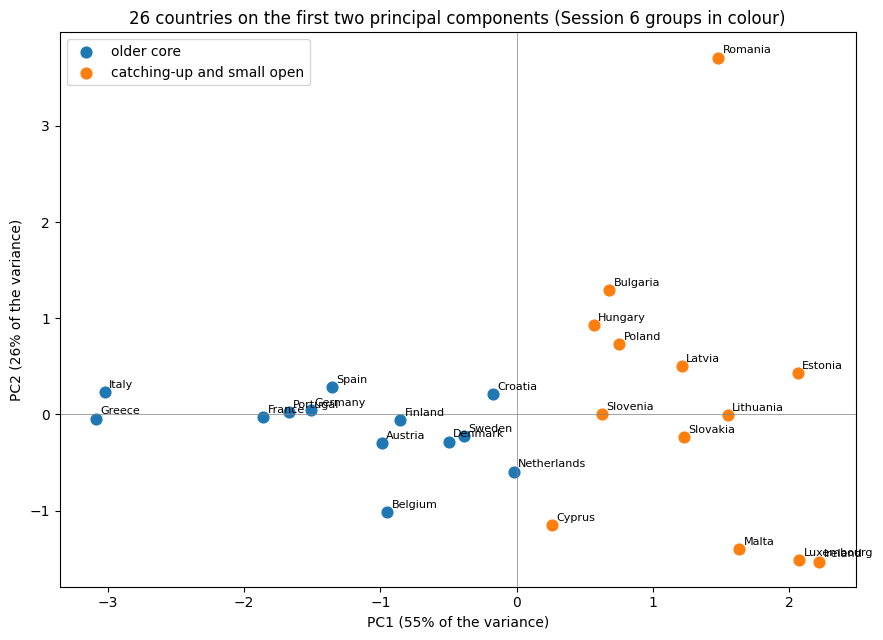

In [3]:
FEATURES_K = ["log trade openness", "debt", "inflation (capped)", "GDP growth"]

def country_averages(frame):
    d = frame.copy()
    d["log trade openness"] = np.log(d["trade_open"])
    d["debt"] = d["debt_gdp"]
    d["inflation (capped)"] = d["inflation"].clip(-30, 30)
    d["GDP growth"] = d["gdp_growth"]
    return d.groupby(COUNTRY)[FEATURES_K].mean()

def zscore(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)

avg = country_averages(df)
Xc = zscore(avg.to_numpy())
countries = avg.index.to_numpy()

# Session 6's two groups (K = 2), checked again here with scikit-learn's k-means
CORE = ["Austria", "Belgium", "Croatia", "Denmark", "Finland", "France", "Germany", "Greece", "Italy", "Netherlands", "Portugal", "Spain", "Sweden"]
group = np.where(np.isin(countries, CORE), "older core", "catching-up and small open")
km = KMeans(n_clusters=2, n_init=100, random_state=0).fit(Xc).labels_
print("Same two groups as Session 6:", len(set(zip(km, group))) == 2)

pca_c = PCA().fit(Xc)
Zc = pca_c.transform(Xc)
print("Explained variance ratio:", np.round(pca_c.explained_variance_ratio_, 3),
      "| first two together:", round(pca_c.explained_variance_ratio_[:2].sum(), 3))
weights_c = pd.DataFrame(pca_c.components_[:2].T, index=FEATURES_K, columns=["PC1", "PC2"])
print(weights_c.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 6.5))
for g, colour in [("older core", "tab:blue"), ("catching-up and small open", "tab:orange")]:
    m = group == g
    ax.scatter(Zc[m, 0], Zc[m, 1], s=60, color=colour, label=g)
for (x, y), c in zip(Zc[:, :2], countries):
    ax.annotate(c, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel(f"PC1 ({pca_c.explained_variance_ratio_[0]:.0%} of the variance)")
ax.set_ylabel(f"PC2 ({pca_c.explained_variance_ratio_[1]:.0%} of the variance)")
ax.set_title("26 countries on the first two principal components (Session 6 groups in colour)"); ax.legend()
plt.tight_layout(); plt.show()

In [4]:
# What each component is made of, in plain words: the inputs with the largest weights and their direction
def words(weights):
    ranked = weights.abs().sort_values(ascending=False)
    parts = [f"{'more' if weights[f] > 0 else 'less'} {f.replace(' (capped)', '')} ({weights[f]:+.2f})" for f in ranked.index if abs(weights[f]) >= 0.3]
    return ", ".join(parts)
for pc in ["PC1", "PC2"]:
    print(f"{pc}: higher values mean {words(weights_c[pc])}")
recon = pca_c.inverse_transform(np.c_[Zc[:, :2], np.zeros((len(Zc), Xc.shape[1] - 2))])
print(f"Reconstruction from two components: average squared error {np.mean((Xc - recon) ** 2):.3f} "
      f"(z-score units; 1 - variance explained = {1 - pca_c.explained_variance_ratio_[:2].sum():.3f})")

PC1: higher values mean more GDP growth (+0.57), less debt (-0.56), more log trade openness (+0.51), more inflation (+0.30)
PC2: higher values mean more inflation (+0.83), less log trade openness (-0.50)
Reconstruction from two components: average squared error 0.186 (z-score units; 1 - variance explained = 0.186)


## 2. PCA on country-years

The same idea on single years: about 750 points, one per country and year. Consolidation episodes (ΔCAPB ≥ 1.5 pp) are in orange; the flagged data artefacts and the other known oddities are labelled.

754 country-years | explained variance ratio: [0.415 0.235 0.2   0.117 0.034]
                         PC1   PC2
log trade openness      0.27 -0.54
debt (square root)     -0.40  0.55
inflation (signed log)  0.24 -0.33
GDP growth              0.62  0.31
TFP growth (1 year)     0.58  0.44
PC1: higher values mean more GDP growth (+0.62), more TFP growth (1 year) (+0.58), less debt (square root) (-0.40)
PC2: higher values mean more debt (square root) (+0.55), less log trade openness (-0.54), more TFP growth (1 year) (+0.44), less inflation (signed log) (-0.33), more GDP growth (+0.31)


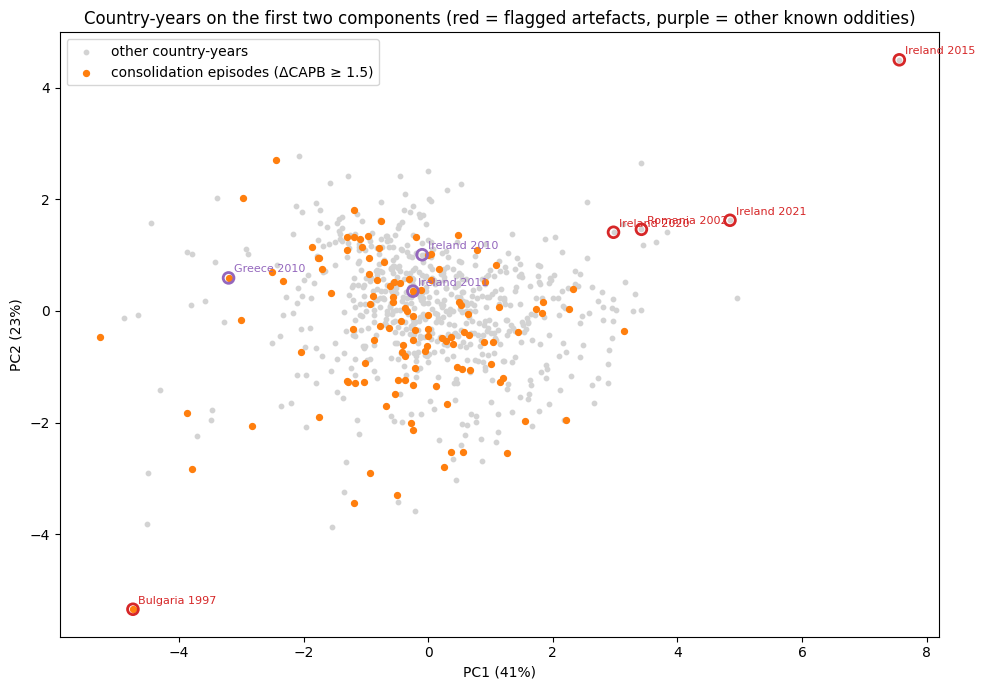

Average position of episodes: PC1 -0.42, PC2 -0.34 (other years: +0.08, +0.06)


In [5]:
FEATURES_Y = ["log trade openness", "debt (square root)", "inflation (signed log)", "GDP growth", "TFP growth (1 year)"]
cy = df.copy()
cy["log trade openness"] = np.log(cy["trade_open"])
cy["debt (square root)"] = np.sqrt(cy["debt_gdp"])
cy["inflation (signed log)"] = np.sign(cy["inflation"]) * np.log1p(cy["inflation"].abs())
cy["GDP growth"] = cy["gdp_growth"]
cy = cy.dropna(subset=FEATURES_Y)
Xy = zscore(cy[FEATURES_Y].to_numpy())
pca_y = PCA().fit(Xy)
Zy = pca_y.transform(Xy)
print(f"{len(cy)} country-years | explained variance ratio:", np.round(pca_y.explained_variance_ratio_, 3))
weights_y = pd.DataFrame(pca_y.components_[:2].T, index=FEATURES_Y, columns=["PC1", "PC2"])
print(weights_y.round(2).to_string())
for pc in ["PC1", "PC2"]:
    print(f"{pc}: higher values mean {words(weights_y[pc])}")

episode = (cy[DCAPB] >= 1.5).to_numpy()
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(Zy[~episode, 0], Zy[~episode, 1], s=10, color="lightgrey", label="other country-years")
ax.scatter(Zy[episode, 0], Zy[episode, 1], s=18, color="tab:orange", label="consolidation episodes (ΔCAPB ≥ 1.5)")
for c, y in ARTEFACTS + OTHER_KNOWN:
    i = np.where((cy[COUNTRY] == c).to_numpy() & (cy[YEAR] == y).to_numpy())[0]
    if len(i):
        colour = "tab:red" if (c, y) in ARTEFACTS else "tab:purple"
        ax.scatter(Zy[i, 0], Zy[i, 1], s=60, facecolors="none", edgecolors=colour, linewidths=2)
        ax.annotate(f"{c} {y}", (Zy[i[0], 0], Zy[i[0], 1]), fontsize=8, color=colour, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel(f"PC1 ({pca_y.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca_y.explained_variance_ratio_[1]:.0%})")
ax.set_title("Country-years on the first two components (red = flagged artefacts, purple = other known oddities)"); ax.legend(loc="best")
plt.tight_layout(); plt.show()
print(f"Average position of episodes: PC1 {Zy[episode, 0].mean():+.2f}, PC2 {Zy[episode, 1].mean():+.2f} "
      f"(other years: {Zy[~episode, 0].mean():+.2f}, {Zy[~episode, 1].mean():+.2f})")

## 3. Collaborative filtering: one-year TFP growth as a ratings table

**Course link:** the collaborative filtering lab. Each country *i* gets a learned vector **w** and bias *b*; each year *j* gets learned features **x**. The prediction for a cell is **w**·**x** + *b*. The cost is half the squared error over the *known* cells plus λ/2 times the squares of all **w** and **x**, minimised with `GradientTape` and Adam.

**Mean normalization:** first the baseline *country average + year average* is subtracted (fitted on the training cells only), so the learned part only has to explain what the averages miss. With 0 learned features, the prediction *is* the baseline.

In [6]:
Y_full = df.pivot(index=COUNTRY, columns=YEAR, values="TFP growth (1 year)")
Y_full = Y_full.loc[:, Y_full.notna().any()]
print("Table:", Y_full.shape, "countries × years |", int(Y_full.notna().sum().sum()), "known cells")

def baseline_fit(Y, R):
    # country average + year average (two-way averages on the known cells, found by a few alternating passes)
    mu = Y[R].mean()
    a, c = np.zeros(Y.shape[0]), np.zeros(Y.shape[1])
    for _ in range(20):
        a = np.nanmean(np.where(R, Y - mu - c[None, :], np.nan), axis=1)
        c = np.nanmean(np.where(R, Y - mu - a[:, None], np.nan), axis=0)
        a, c = np.nan_to_num(a), np.nan_to_num(c)
    return mu + a[:, None] + c[None, :]

def cf_fit(Y, R, n, lam, steps=500, seed=0):
    # Y: residuals after the baseline; R: True where the cell is a training cell
    tf.random.set_seed(seed)
    W = tf.Variable(tf.random.normal((Y.shape[0], n), stddev=0.1))
    b = tf.Variable(tf.zeros((Y.shape[0], 1)))
    X = tf.Variable(tf.random.normal((Y.shape[1], n), stddev=0.1))
    Yt, Rt = tf.constant(np.nan_to_num(Y), tf.float32), tf.constant(R, tf.float32)
    opt = tf.keras.optimizers.Adam(learning_rate=0.05)

    @tf.function
    def step():
        with tf.GradientTape() as tape:
            err = (tf.matmul(W, X, transpose_b=True) + b - Yt) * Rt
            J = 0.5 * tf.reduce_sum(err ** 2) + lam / 2 * (tf.reduce_sum(W ** 2) + tf.reduce_sum(X ** 2))
        grads = tape.gradient(J, [W, b, X])
        opt.apply_gradients(zip(grads, [W, b, X]))
        return J
    for _ in range(steps):
        step()
    return W.numpy(), b.numpy(), X.numpy()

def predict(Y, R, n, lam, seed=0):
    base = baseline_fit(Y, R)
    if n == 0:
        return base
    W, b, X = cf_fit(np.where(R, Y - base, 0.0), R, n, lam, seed=seed)
    return base + W @ X.T + b

N_FEATURES, LAMBDAS = [1, 2, 3], [0.3, 1, 3, 10, 30]

def choose(Y, R, seed):
    # 5-fold cross-validation inside the training cells only
    rng = np.random.default_rng(1000 + seed)
    cells = np.argwhere(R)
    folds = np.array_split(rng.permutation(len(cells)), 5)
    scores = {}
    for n in N_FEATURES:
        for lam in LAMBDAS:
            err = []
            for f in folds:
                R_in = R.copy(); R_in[tuple(cells[f].T)] = False
                P = predict(Y, R_in, n, lam, seed)
                err.append(((P - Y)[tuple(cells[f].T)]) ** 2)
            scores[(n, lam)] = np.mean(np.concatenate(err))
    return min(scores, key=scores.get), scores

def evaluate(Y_table, n_hides=10):
    Y = Y_table.to_numpy(); known = ~np.isnan(Y)
    out, per_n = [], {n: [] for n in N_FEATURES}
    for seed in range(n_hides):
        rng = np.random.default_rng(seed)
        cells = np.argwhere(known)
        test = cells[rng.permutation(len(cells))[: int(0.2 * len(cells))]]
        R = known.copy(); R[tuple(test.T)] = False
        (n, lam), scores = choose(Y, R, seed)
        y_test = Y[tuple(test.T)]
        mse = lambda P: np.mean((P[tuple(test.T)] - y_test) ** 2)
        row = {"hide": seed, "chosen features": n, "chosen λ": lam,
               "overall mean": np.mean((Y[R].mean() - y_test) ** 2),
               "country average only": mse(np.nanmean(np.where(R, Y, np.nan), axis=1)[:, None] + 0 * Y),
               "baseline: country + year average": mse(predict(Y, R, 0, 0)),
               "collaborative filtering": mse(predict(Y, R, n, lam, seed))}
        row["gain vs baseline %"] = 100 * (1 - row["collaborative filtering"] / row["baseline: country + year average"])
        out.append(row)
        for k in N_FEATURES:   # each number of features with its own best λ (from the same cross-validation)
            lam_k = min((s for s in scores if s[0] == k), key=scores.get)[1]
            per_n[k].append(100 * (1 - mse(predict(Y, R, k, lam_k, seed)) / row["baseline: country + year average"]))
    return pd.DataFrame(out).set_index("hide"), per_n

res, per_n = evaluate(Y_full)
print(res.round(2).to_string())
print()
print(f"Collaborative filtering beats the baseline in {int((res['gain vs baseline %'] > 0).sum())} of {len(res)} hides; "
      f"median gain {res['gain vs baseline %'].median():+.1f} % (range {res['gain vs baseline %'].min():+.1f} to {res['gain vs baseline %'].max():+.1f})")
print("Mean squared error over the 10 hides:", res[["overall mean", "country average only", "baseline: country + year average", "collaborative filtering"]].mean().round(2).to_dict())
print("Gain vs baseline with a fixed number of features (median over hides):", {k: round(float(np.median(v)), 1) for k, v in per_n.items()})

Table: (26, 29) countries × years | 754 known cells


      chosen features  chosen λ  overall mean  country average only  baseline: country + year average  collaborative filtering  gain vs baseline %
hide                                                                                                                                              
0                   2        10          8.73                  8.76                              7.11                     6.98                1.85
1                   2        30          5.66                  5.55                              4.09                     4.09               -0.00
2                   3        10          6.24                  5.76                              4.39                     4.27                2.68
3                   1        30         10.25                 10.02                              6.83                     6.83                0.00
4                   3        10          8.46                  8.13                              5.72                 

## 4. Related countries

**Course link:** *finding related items*: items whose learned feature vectors are close together are similar. Here: countries whose year-to-year TFP growth moves the same way (learned features, fitted on all known cells with 3 features and the λ that cross-validation prefers for 3), and countries with similar average conditions (position on the first two principal components of section 1). The two notions are different: one is about co-movement over time, the other about levels.

Learned features are not unique (a different random start can rotate them), so the neighbour lists are also compared across three random starts.

In [7]:
def related_by_cf(Y_table, n=3, seeds=(0, 1, 2)):
    Y = Y_table.to_numpy(); R = ~np.isnan(Y)
    _, scores = choose(Y, R, seed=0)
    lam = min((s for s in scores if s[0] == n), key=scores.get)[1]
    base = baseline_fit(Y, R)
    lists = []
    for s in seeds:
        W, b, X = cf_fit(np.where(R, Y - base, 0.0), R, n, lam, seed=s)
        D = ((W[:, None, :] - W[None, :, :]) ** 2).sum(axis=2)
        np.fill_diagonal(D, np.inf)
        lists.append([list(Y_table.index[np.argsort(D[i])[:3]]) for i in range(len(W))])
    return lists, lam

def related_by_pca(Z):
    D = ((Z[:, None, :2] - Z[None, :, :2]) ** 2).sum(axis=2)
    np.fill_diagonal(D, np.inf)
    return [list(countries[np.argsort(D[i])[:3]]) for i in range(len(Z))]

cf_lists, lam_cf = related_by_cf(Y_full)
pca_lists = related_by_pca(Zc)
assert list(Y_full.index) == list(countries)
stable = np.mean([len(set(cf_lists[0][i]) & set(cf_lists[s][i])) / 3 for s in (1, 2) for i in range(len(countries))])
overlap = np.mean([len(set(cf_lists[0][i]) & set(pca_lists[i])) / 3 for i in range(len(countries))])
print(f"Learned features: 3, λ = {lam_cf:g}. Same neighbours across random starts: {stable:.0%} | overlap between the two lists: {overlap:.0%}")
pd.DataFrame({"nearest by learned TFP features": [", ".join(l) for l in cf_lists[0]],
              "nearest by PCA position (average conditions)": [", ".join(l) for l in pca_lists]}, index=countries)

Learned features: 3, λ = 30. Same neighbours across random starts: 19% | overlap between the two lists: 17%


,nearest by learned TFP features,nearest by PCA position (average conditions)
Austria,"Latvia, Estonia, Hungary","Finland, Denmark, Sweden"
Belgium,"Italy, Bulgaria, France","Austria, Denmark, Finland"
Bulgaria,"France, Cyprus, Germany","Hungary, Poland, Latvia"
Croatia,"Poland, Belgium, Ireland","Sweden, Denmark, Finland"
Cyprus,"Germany, Hungary, France","Netherlands, Sweden, Denmark"
Denmark,"Netherlands, Ireland, Poland","Sweden, Finland, Austria"
Estonia,"Hungary, Latvia, Germany","Lithuania, Latvia, Slovakia"
Finland,"Sweden, Austria, Latvia","Austria, Denmark, Sweden"
France,"Bulgaria, Cyprus, Germany","Portugal, Germany, Spain"
Germany,"Cyprus, Hungary, France","Portugal, Spain, France"


## 5. Without the flagged data artefacts

Bulgaria 1997, Ireland 2015, 2020 and 2021, and Romania 2002 are removed: from the country averages (section 1), from the country-years (section 2), and as cells of the TFP table (sections 3 and 4). Does anything important change?

In [8]:
clean = df[~is_artefact]

# 1. PCA on countries
avg2 = country_averages(clean)
Xc2 = zscore(avg2.to_numpy())
pca_c2 = PCA().fit(Xc2)
Zc2 = pca_c2.transform(Xc2)
sign = np.sign((pca_c2.components_[:2] * pca_c.components_[:2]).sum(axis=1))        # PCA signs are arbitrary
Zc2[:, :2] *= sign
print("Countries, explained variance ratio:", np.round(pca_c.explained_variance_ratio_[:2], 3), "->", np.round(pca_c2.explained_variance_ratio_[:2], 3))
print("Correlation of positions with the original: PC1", round(np.corrcoef(Zc[:, 0], Zc2[:, 0])[0, 1], 3), "| PC2", round(np.corrcoef(Zc[:, 1], Zc2[:, 1])[0, 1], 3))
print("Largest change in a weight:", round(np.abs(pca_c2.components_[:2] * sign[:, None] - pca_c.components_[:2]).max(), 2))

# 2. PCA on country-years
cy2 = cy[[(c, y) not in ARTEFACTS for c, y in zip(cy[COUNTRY], cy[YEAR])]]
pca_y2 = PCA().fit(zscore(cy2[FEATURES_Y].to_numpy()))
sign_y = np.sign((pca_y2.components_[:2] * pca_y.components_[:2]).sum(axis=1))
print("\nCountry-years, explained variance ratio:", np.round(pca_y.explained_variance_ratio_[:2], 3), "->", np.round(pca_y2.explained_variance_ratio_[:2], 3))
print("Weights without the artefacts:")
print(pd.DataFrame((pca_y2.components_[:2] * sign_y[:, None]).T, index=FEATURES_Y, columns=["PC1", "PC2"]).round(2).to_string())

# 3. Collaborative filtering
Y_clean = Y_full.copy()
for c, y in ARTEFACTS:
    Y_clean.loc[c, y] = np.nan
res2, per_n2 = evaluate(Y_clean)
print(f"\nCollaborative filtering without the artefacts: beats the baseline in {int((res2['gain vs baseline %'] > 0).sum())} of {len(res2)} hides; "
      f"median gain {res2['gain vs baseline %'].median():+.1f} % (range {res2['gain vs baseline %'].min():+.1f} to {res2['gain vs baseline %'].max():+.1f})")
print("Mean squared error over the 10 hides:", res2[["overall mean", "country average only", "baseline: country + year average", "collaborative filtering"]].mean().round(2).to_dict())
print("Chosen number of features:", res2["chosen features"].value_counts().to_dict(), "| before:", res["chosen features"].value_counts().to_dict())

# 4. Related countries
cf_lists2, _ = related_by_cf(Y_clean, seeds=(0,))
pca_lists2 = related_by_pca(Zc2)
same_cf = np.mean([len(set(cf_lists[0][i]) & set(cf_lists2[0][i])) / 3 for i in range(len(countries))])
same_pca = np.mean([len(set(pca_lists[i]) & set(pca_lists2[i])) / 3 for i in range(len(countries))])
print(f"\nSame nearest countries as before: learned features {same_cf:.0%}, PCA position {same_pca:.0%}")

Countries, explained variance ratio: [0.555 0.26 ] -> [0.573 0.253]
Correlation of positions with the original: PC1 0.997 | PC2 0.994
Largest change in a weight: 0.05

Country-years, explained variance ratio: [0.415 0.235] -> [0.423 0.234]
Weights without the artefacts:
                         PC1   PC2
log trade openness      0.24 -0.66
debt (square root)     -0.40  0.53
inflation (signed log)  0.31 -0.14
GDP growth              0.61  0.29
TFP growth (1 year)     0.56  0.43



Collaborative filtering without the artefacts: beats the baseline in 8 of 10 hides; median gain +2.1 % (range -0.1 to +9.8)
Mean squared error over the 10 hides: {'overall mean': 5.94, 'country average only': 5.82, 'baseline: country + year average': 4.08, 'collaborative filtering': 3.93}
Chosen number of features: {3: 4, 1: 4, 2: 2} | before: {1: 5, 2: 3, 3: 2}



Same nearest countries as before: learned features 22%, PCA position 94%


# Learning log, Session 7 (14 Nov 2026)

**Course:** Machine Learning Specialization, Course 3 Week 2 (collaborative filtering: learned features, cost function, mean normalization, cold start, TensorFlow `GradientTape` and Adam; content-based filtering; PCA: principal components, explained variance, projection, reconstruction)

**Questions:** what do the 26 countries look like in one picture? Can collaborative filtering predict missing one-year TFP growth better than simple averages?

**Setup, decided before fitting:**
- **PCA on countries:** the same z-scored 1995–2024 averages as Session 6 (log trade openness, debt, inflation capped at ±30 %, GDP growth), coloured by Session 6's K = 2 groups. scikit-learn's k-means reproduces those two groups exactly.
- **PCA on country-years:** 754 country-years, Session 6's transformed inputs (log trade openness, square-root debt, signed-log inflation, GDP growth, one-year TFP growth), z-scored. ΔCAPB is left out, so episodes sit where their conditions put them.
- **Collaborative filtering:** the 26 × 29 table of one-year TFP growth (754 known cells); countries = users, years = items. 20 % of the known cells hidden at random, 10 times. Baseline = country average + year average on the training cells, which is also the mean normalization: the learned part models what is left. My own cost (half the squared error on known cells + λ/2 times the squares of all learned features), minimised with `GradientTape` and Adam (learning rate 0.05, 500 steps). 1, 2 or 3 learned features and λ ∈ {0.3, 1, 3, 10, 30} chosen by 5-fold cross-validation inside the training cells.
- This fills gaps in a country's own record; it is not an unseen-country test. A country with no known years would be a cold start.
- Rerun without the flagged artefacts: Bulgaria 1997, Ireland 2015, 2020 and 2021, Romania 2002. The notebook runs in about 6 minutes.

**PCA on the 26 countries: one picture**
- **Explained variance:** PC1 55.5 %, PC2 26.0 %, together 81.4 %; PC3 10.3 %, PC4 8.2 %. Reconstructing the four inputs from two components leaves an average squared error of 0.186 (in z-scores), which is exactly the 18.6 % not explained.
- **PC1 (left to right):** from high-debt, slow-growing, closed economies to fast-growing, low-debt, open ones (weights: GDP growth +0.57, debt −0.56, log trade openness +0.51, inflation +0.30). It is the "catching-up vs older core" axis.
- **PC2 (bottom to top):** higher inflation and less trade openness (inflation +0.83, log trade openness −0.50).
- **Where countries sit:** Session 6's two groups separate cleanly along PC1, with Croatia, Netherlands and Cyprus closest to the middle. Greece and Italy are furthest left (high debt, slow growth). Romania is alone at the top (inflation). Bulgaria, Hungary and Poland are above the catching-up group. Ireland, Luxembourg, Malta and Cyprus are at the bottom right (very open, low inflation).

**PCA on country-years**
- **Explained variance:** PC1 41.5 %, PC2 23.5 % (together 65 %).
- **PC1:** the boom-to-bust axis (GDP growth +0.62, one-year TFP growth +0.58, debt −0.40).
- **PC2:** more debt and less trade openness (debt +0.55, trade openness −0.54), with faster TFP and GDP growth.
- **Consolidation episodes** are spread through the whole cloud, slightly towards lower growth and higher debt (average position PC1 −0.42, PC2 −0.34, against +0.08 and +0.06 for other years). They are not a separate kind of country-year.
- **The flagged artefacts sit at the edges:** Ireland 2015 far top right (the most extreme point), Ireland 2020 and 2021 and Romania 2002 to the right (TFP jumps), Bulgaria 1997 far bottom left (inflation, collapse). Ireland 2010–11 sit in the middle, because their oddity is ΔCAPB, which is not an input here. Greece 2010 is to the left (a bust year).

**Collaborative filtering: does it beat simple averages?**

| Mean squared error on the hidden cells (average of 10 hides) | With all cells | Without the flagged artefacts |
|---|---|---|
| Overall mean | 8.18 | 5.94 |
| Country average only | 7.90 | 5.82 |
| **Baseline: country average + year average** | **6.03** | **4.08** |
| Collaborative filtering (features and λ chosen by cross-validation) | 6.11 | 3.93 |
| Collaborative filtering beats the baseline | 4 of 10 hides, median gain −0.0 % (−8.3 % to +2.7 %) | **8 of 10 hides, median +2.1 % (−0.1 % to +9.8 %)** |
| Chosen number of features | 1 ×5, 2 ×3, 3 ×2 | 3 ×4, 1 ×4, 2 ×2 |

- **The year average does most of the work.** Adding the year average to the country average cuts the error by about a quarter (7.90 → 6.03), because TFP growth moves together across countries in the same year (the 2009 crash, for example).
- **With all cells, learned features add nothing.** Cross-validation often picks λ = 30, which shrinks the learned features almost to zero, so the prediction becomes the baseline (several hides show a gain of exactly 0.0 %). In two hides the learned features made things worse (−8.3 %, −7.2 %).
- **Without the artefacts, a small, fairly steady gain appears:** better than the baseline in 8 of 10 hides, by a median of 2.1 %. The few huge artefact cells (Ireland 2015's +19.8 %, Bulgaria 1997's −13.7 %) dominate the squared error and hide the small pattern the learned features can find.
- In ML terms, the learned features catch a little of how countries' growth moves together beyond the common year effect. It is small, and it is about filling gaps in known countries, not about unseen ones or consolidations.

**Related countries**
- **By learned features** (3 features, λ = 30, all cells): the lists are **not stable**. Only 19 % of the nearest countries are the same across three random starts, and 22 % after dropping the artefacts. With λ = 30 the features are close to zero, so the distances between them are mostly noise. These lists should not be read as "related countries".
- **By PCA position** (average conditions): stable, with 94 % of neighbours unchanged without the artefacts, and easy to read. Greece's nearest are Italy, France and Portugal. Ireland's are Luxembourg, Malta and Slovakia. Estonia's are Lithuania, Latvia and Slovakia. Romania's are Bulgaria, Hungary and Poland.
- Only 17 % overlap between the two kinds of list, as expected given that the learned ones are mostly noise.

**Without the flagged artefacts: does anything important change?**
- **PCA on countries:** almost nothing. Explained variance moves from 55.5 % / 26.0 % to 57.3 % / 25.3 %. Positions correlate 0.997 (PC1) and 0.994 (PC2) with the original, and no weight changes by more than 0.05. Each artefact is one year in a 30-year average.
- **PCA on country-years:** the components keep their meaning (41.5 % → 42.3 % and 23.5 % → 23.4 %). Trade openness weighs more on PC2 (−0.54 → −0.66) and inflation less (−0.33 → −0.14).
- **Collaborative filtering: the one thing that changes.** It goes from no gain to a small, steady gain (above). So the artefacts matter for anything scored by squared error on single years.
- **Related countries:** the PCA neighbours barely move (94 % the same); the learned-feature neighbours are unstable either way.

**Main lessons**
- Two principal components capture 81 % of how the countries differ in average conditions, and the first one is Session 6's two-group split.
- Consolidation episodes do not form their own region of the data; they happen in all kinds of conditions, a little more often in bad ones.
- For one-year TFP growth, "country average + year average" is a strong baseline, and the year average is most of it.
- Learned features help only a little, and only once a handful of artefact cells are removed: squared error lets a few extreme cells drown a weak pattern.
- When regularization pushes learned features towards zero, "nearest neighbours" in that feature space are noise. Check stability across random starts before reading them.
- PCA and the data-artefact checks say the same as Session 6: a few country-years are not real economics and should be handled before any model is judged on single years.

**Next:** Course 3 Week 3 (reinforcement learning).